In [1]:
import os
import sys
import json
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.export import export


In [2]:
class SimpleCNNF(nn.Module):
    def __init__(self):
        super(SimpleCNNF, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))  # Output: (16, 14, 14)
        x = F.relu(self.conv2(x))  # Output: (32, 7, 7)
        return x


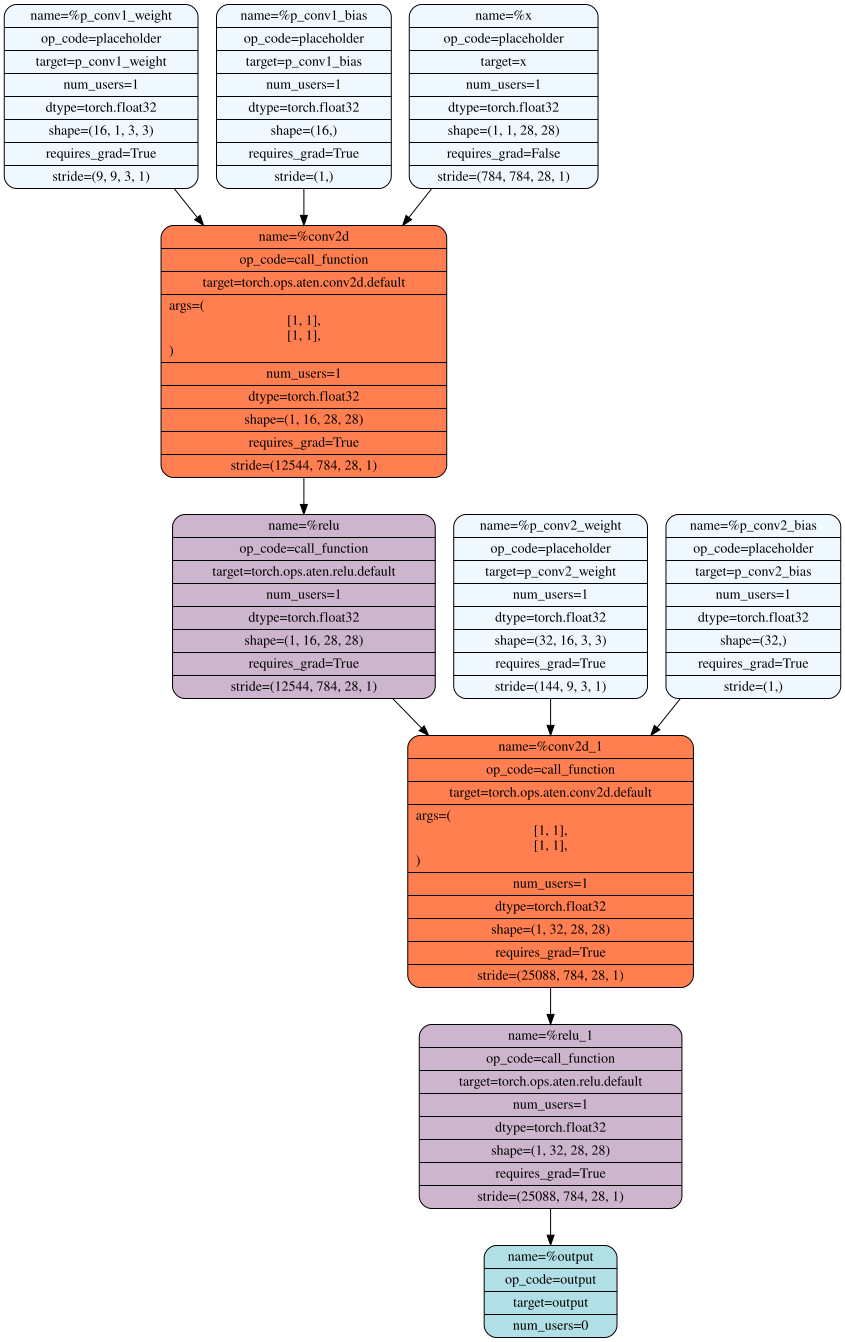

In [3]:
from utils.drawer import draw_graph
# Create model and sample input
model = SimpleCNNF()
model.eval()

# Export to FX graph
sample_input = torch.randn(1, 1, 28, 28)
exported_program = export(model, (sample_input,), strict=False)
graph_module = exported_program.graph_module

draw_graph(graph_module)


In [4]:
from torchao.quantization.pt2e.quantize_pt2e import prepare_pt2e, convert_pt2e
from mxpt2e.quantizer import MXQuantizer, get_symmetric_quantization_mx_config
from executorch.backends.xnnpack.quantizer.xnnpack_quantizer import (
    get_symmetric_quantization_config,
    XNNPACKQuantizer,
)

quantizer = MXQuantizer()
quantizer.set_global(
    get_symmetric_quantization_mx_config(observer_type="minmax", block_size=32, quantize_weights=True, is_per_channel=True)
    # get_symmetric_quantization_config()
)
prepared = prepare_pt2e(graph_module, quantizer)


Failed to load /usr/local/lib/python3.12/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.12/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.12/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.12/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


In [5]:
converted = convert_pt2e(prepared, use_reference_representation=False)


/usr/local/lib/python3.12/dist-packages/torchao/quantization/pt2e/utils.py:148: UserWarning: must run observer before calling calculate_qparams. Returning default values.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchao/quantization/pt2e/utils.py:156: UserWarning: must run observer before calling calculate_qparams. Returning default values.
  warnings.warn(


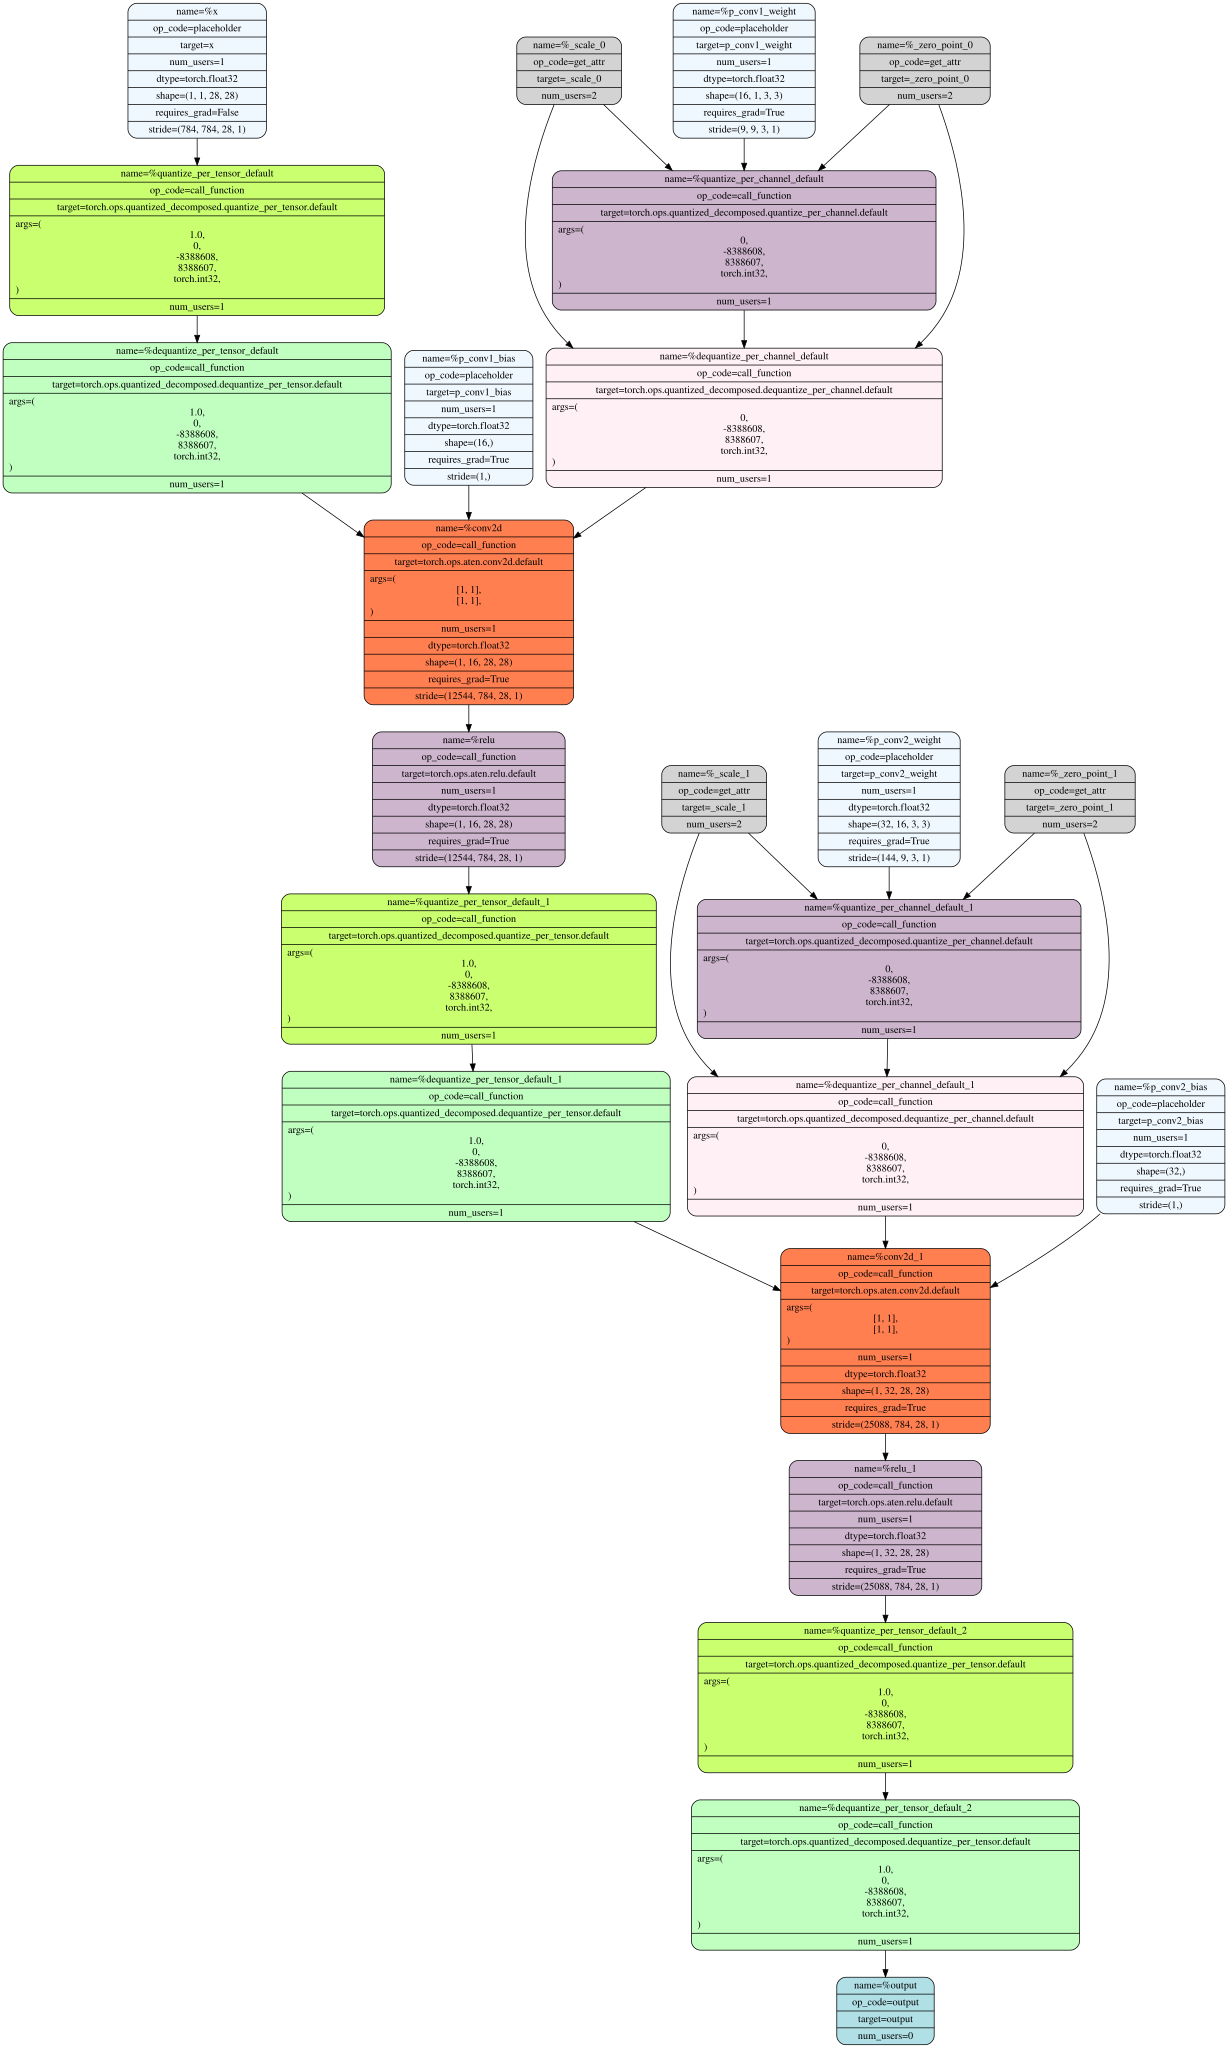

In [6]:
draw_graph(converted)

In [9]:
# Insert MX stage
from mxpt2e.convert_pass import insert_mx_quant_dequant_after_int24_dq
converted = insert_mx_quant_dequant_after_int24_dq(converted, block_size=32)


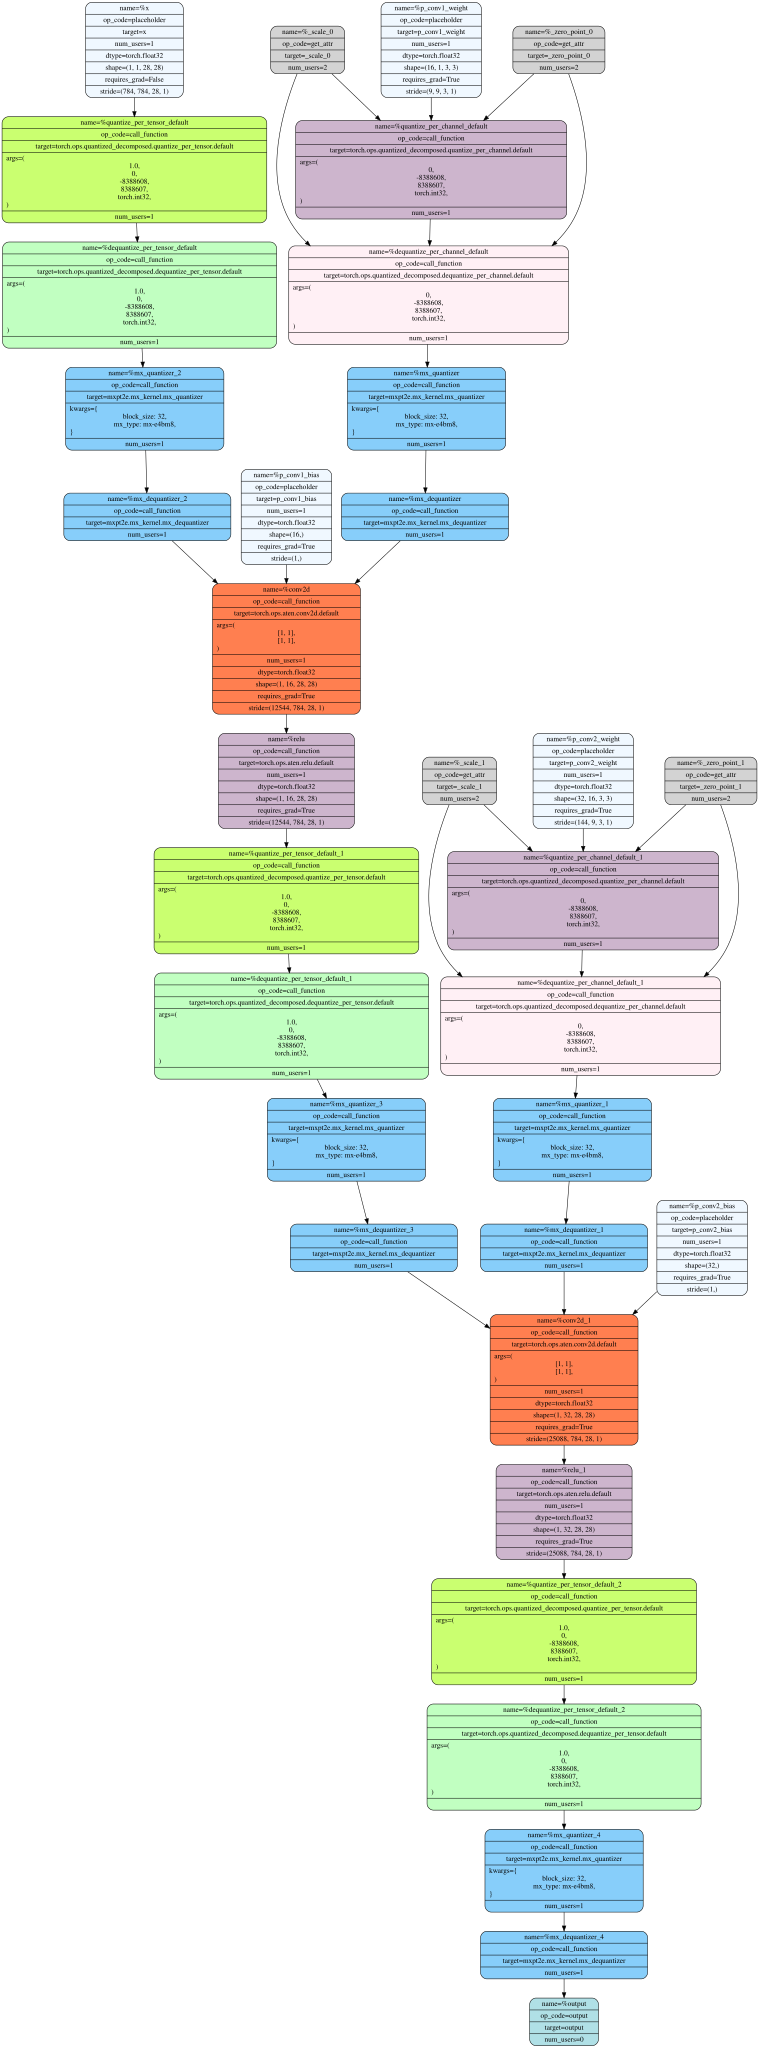

In [10]:
draw_graph(converted)

# qp exporter

In [7]:
import sys, os

base = os.path.abspath("../IR_EXPORTER/quantization_platform/")  # the notebook's directory (quantization_platform)

# Each package's actual source root:
sys.path.insert(0, os.path.join(base, "quantization-pipeline", "src"))
sys.path.insert(0, os.path.join(base, "quantization-core"))       # no src/ wrapper
sys.path.insert(0, os.path.join(base, "qp-utils", "src"))

In [8]:
from quantization_pipeline.export_ir import ExportDriver

ed = ExportDriver()
p = ed.export(converted, output_dir="dump", submodule_name='test_graph')

2026-10-04 11:35:17.417 | INFO     | quantization_pipeline.modifications.base.model_modification_base:_log_application:87 - Modification 'shape_normalization' applied successfully. shapes normalized to batch size 1
2026-10-04 11:35:17.417 | INFO     | quantization_pipeline.export_ir.exporter:_stage1_validate:293 - Stage 1: Validating graph...
2026-10-04 11:35:17.418 | INFO     | quantization_pipeline.export_ir.stage1_validation:validate_operators:109 - Operator validation passed: all ops in operator_map
2026-10-04 11:35:17.419 | INFO     | quantization_pipeline.export_ir.stage1_validation:validate_quantization:140 - Quantization validation passed
2026-10-04 11:35:17.419 | INFO     | quantization_pipeline.export_ir.stage1_validation:validate_relu_quantization:171 - ReLU quantization validation passed
2026-10-04 11:35:17.420 | INFO     | quantization_pipeline.export_ir.stage1_validation:validate_static_shapes:201 - Static shape validation passed
2026-10-04 11:35:17.476 | INFO     | quant